# 내구 실행 모드 비교

**이 노트북에서 할 일**

1. 노드 둘인 그래프를 저장 시점 셋으로 끝까지 실행해, 남은 체크포인트 수를 견줍니다.
2. 같은 그래프를 자식 프로세스로 띄우고 둘째 노드에서 강제로 끝낸 뒤, 파일에 남은 것을 읽습니다.
3. 새 프로세스로 같은 스레드를 다시 실행해, 어느 노드부터 다시 실행되는지 기록 파일로 봅니다.

**준비물** — 이 노트북은 모델을 부르지 않습니다.
모델 요청은 0번이고, API 키 없이 실행합니다.
01절처럼 매번 같은 값을 내는 우리 노드로, 저장된 값이 맞는지 출력으로 가릅니다.

실습 폴더 맨 위의 스크립트 `durability_worker.py`를 자식 프로세스로 실행합니다.
자식 프로세스는 모두 19번 띄우고, 그중 17번을 강제로 끝냅니다.
6절의 되풀이 장면은 저장 시점마다 다섯 번입니다.

노트북은 빈 임시 폴더를 만들어 그 폴더에서 실행합니다.
SQLite 파일·신호 파일·기록 파일은 모두 이 임시 폴더에 생기고, 실습 폴더에는 파일을 남기지 않습니다.
읽어 오는 자료 파일은 없습니다.
교재 출력을 만든 실행에서는 노트북 전체가 30초 안에 끝났습니다.
설치 셀에 걸리는 시간은 네트워크에 따라 달라집니다.

**기준 버전** — 첫 셀에서 패키지 둘을 설치합니다.
그래프는 langgraph 1.2.11입니다.
SQLite 체크포인터는 langgraph-checkpoint-sqlite 3.0.3에 들어 있습니다.

교재 출력은 Linux의 Python 3.12.13과, 그 Python에 들어 있는 SQLite 3.53.1로 만들었습니다.
프로세스를 강제로 끝내는 방식과 종료 코드는 운영체제마다 다릅니다.
Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~5절을 읽습니다.
저장 시점 셋을 견주고, `exit`와 `sync`로 실행하다 끊는 자리입니다.
6절은 같은 장면을 저장 시점마다 다섯 번씩 되풀이하는 자리이고, 실습 시간에 실행합니다.
4~6절의 끊는 셀은 실행할 때마다 새 파일을 써서, 다시 실행해도 같은 결과가 나옵니다.
노트북 전체를 처음 값으로 다시 보려면 1절 임시 폴더 셀부터 다시 실행합니다.

실습 폴더 `labs/part6/ch23-persistence`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 상자 여섯이 한 줄로 이어진 흐름도이고, 위 네 상자는 회색 테두리 칸 4·5절 셀 하나 안에서 이어집니다. 첫 파란 상자는 start_worker first-run 단계로 띄움입니다. 둘째 파란 상자는 자식 프로세스 first를 마치고 second에 들어감 신호 파일을 만들고 30초 쉼입니다. 셋째 노란 상자는 wait_for_signal 신호 파일이 생겼는가 True, 넷째 노란 상자는 stop_worker kill 뒤 종료 코드 -9입니다. 다섯째 파란 상자는 read_saved 새 연결로 SQLite 파일을 읽음, 여섯째 파란 상자는 start_worker resume 단계로 다시 띄우고 wait로 끝날 때까지 기다림인 그림](attachment:04-2-둘째-노드에서-끊고-다시-실행하는-차례.png)

위에서 아래로 한 줄로 읽습니다.
파란 상자는 우리가 적은 함수와 스크립트가 하는 일이고, 노란 상자는 노트북 4·5절 출력입니다.
회색 테두리 칸 안의 네 상자는 4·5절에서 한 셀로 실행하고, 신호 파일이 생기면 바로 끊습니다.
그래서 끊는 자리는 늘 둘째 노드가 쉬는 동안입니다.
맨 아래 상자의 새 자식 프로세스는 끊긴 프로세스가 쓰던 파일을 그대로 엽니다.
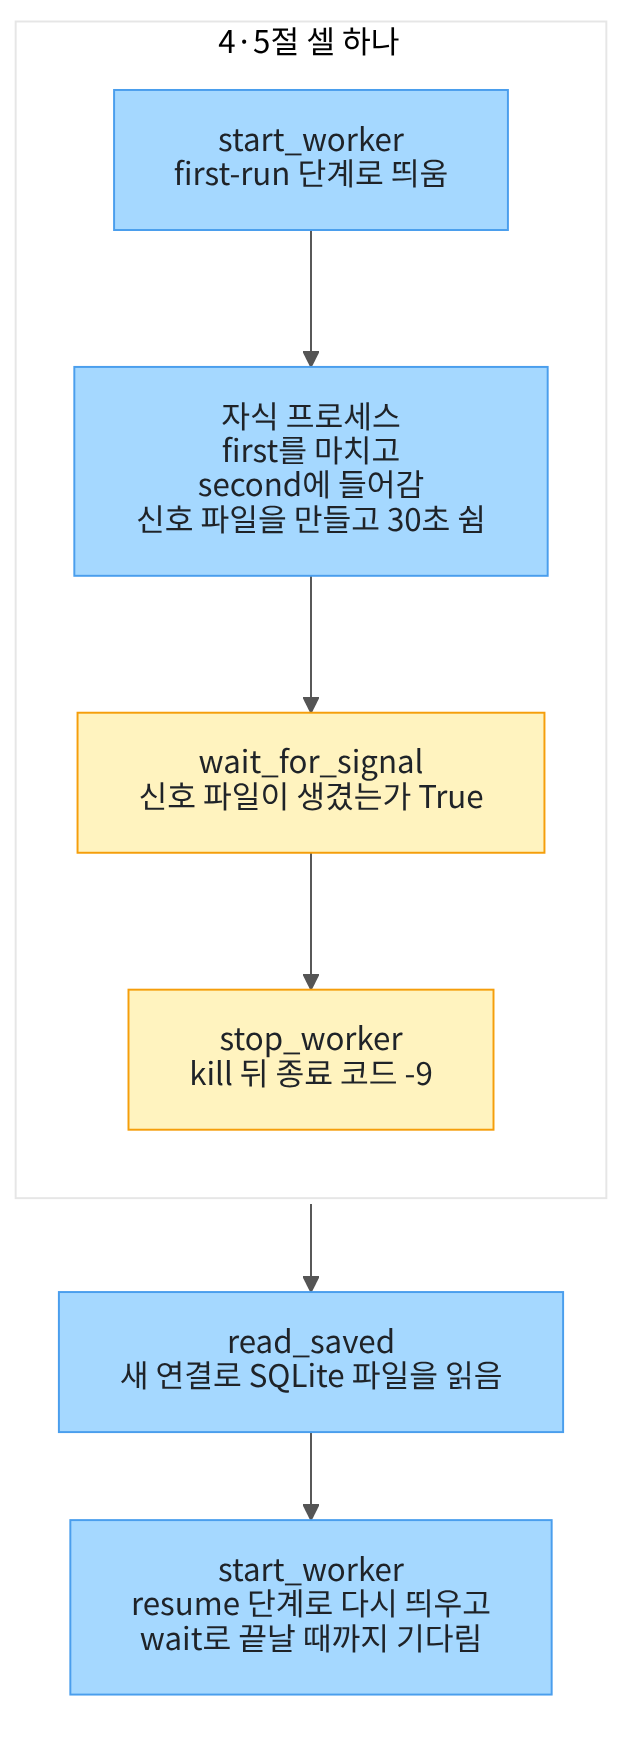

## 1. 준비

01절에서 체크포인터를 붙이면 단계를 하나 마칠 때마다 상태가 저장된다고 배웠습니다.
03절에서는 체크포인트를 SQLite 파일에 쓰고, 연결을 새로 열어 대화를 이어 갔습니다.
이 절은 그 저장을 언제 끝내는지 고르는 인자 `durability`를 봅니다.
그리고 프로그램을 도중에 강제로 끝낸 뒤, 파일에 무엇이 남는지 확인합니다.

첫 셀은 패키지 둘을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langgraph==1.2.11" "langgraph-checkpoint-sqlite==3.0.3"
from importlib.metadata import version

print("langgraph:", version("langgraph"))
print("langgraph-checkpoint-sqlite:", version("langgraph-checkpoint-sqlite"))

Note: you may need to restart the kernel to use updated packages.
langgraph: 1.2.11
langgraph-checkpoint-sqlite: 3.0.3


**결과 읽기** — 출력 줄 `langgraph: 1.2.11`과 `langgraph-checkpoint-sqlite: 3.0.3`이 보입니다.
두 판 모두 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-25에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
상태 형식과 그래프 이름은 Ch 13 01·02절, `sqlite3`와 `SqliteSaver`는 03절과 같습니다.
모듈 `subprocess`와 `sys`는 Ch 2 08절에서 pytest를 새 Python으로 실행할 때 썼습니다.
모듈 `time`은 Ch 15 05절과 Ch 16 05절에서, 모듈 `os`는 01절 임시 폴더 셀에서 썼습니다.

In [2]:
# 그래프 이름(Ch 13 01·02절)과 SQLite 체크포인터(03절)에, 자식 프로세스를 다룰 모듈을 더해 가져옵니다
import operator
import os
import sqlite3
import subprocess
import sys
import time
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.sqlite import SqliteSaver

print("이 챕터에서 처음 가져온 모듈:", "subprocess, sys, time")
print("SQLite 판:", sqlite3.sqlite_version)

이 챕터에서 처음 가져온 모듈: subprocess, sys, time
SQLite 판: 3.53.1


**결과 읽기** — 출력 줄 `SQLite 판: 3.53.1`은 03절과 같은 판입니다.
세 모듈은 과정에서 쓴 적이 있지만, 이 챕터에서는 처음 가져옵니다.

다음 셀은 실습 폴더 맨 위의 스크립트 `durability_worker.py` 자리를 찾습니다.
Ch 17 05절에서 자료 폴더를 찾은 셀과 같은 모양으로, 후보 자리 셋을 차례로 봅니다.
함수 `os.path.abspath`는 지금 작업 폴더 기준의 자리를, 컴퓨터 맨 위부터 적은 자리 글로 바꿉니다.
다음 셀에서 임시 폴더로 옮긴 뒤에도 이 파일을 찾으려고 씁니다.

In [3]:
# 실습 폴더 맨 위의 스크립트 durability_worker.py 자리를 찾습니다(임시 폴더로 옮기기 전에 합니다)
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part6/ch23-persistence/durability_worker.py"):
        root_path = candidate
        break
print("찾은 프로젝트 맨 위:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."
# abspath()는 지금 작업 폴더 기준의 자리를, 컴퓨터 맨 위부터 적은 자리 글로 바꿉니다(자리 글은 출력하지 않음)
worker_path = os.path.abspath(root_path + "/labs/part6/ch23-persistence/durability_worker.py")
print("worker 파일이 있는가:", os.path.exists(worker_path))

찾은 프로젝트 맨 위: .
worker 파일이 있는가: True


**결과 읽기** — 출력 줄 `찾은 프로젝트 맨 위: .`은 교재 출력을 프로젝트 맨 위에서 실행했다는 뜻입니다.
노트북을 `notebooks/` 폴더에서 열면 이 줄에 `../../../..`가 찍힙니다.
출력 줄 `worker 파일이 있는가: True`로, 스크립트 자리를 변수 `worker_path`에 담았습니다.
자리 글은 컴퓨터마다 달라 출력하지 않았습니다.

다음 셀은 01절처럼 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다.
이 절의 SQLite 파일·신호 파일·기록 파일은 모두 이 임시 폴더에 생깁니다.
자식 프로세스도 이 폴더를 작업 폴더로 물려받아, 같은 폴더에 파일을 씁니다.

In [4]:
# 파일이 생기는지 볼 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다(Ch 4 03절과 같은 모양)
import os
import tempfile

# mkdtemp()는 운영체제 임시 폴더 안에 새 폴더를 만들고, 그 폴더의 위치를 글로 내놓습니다
practice_folder = tempfile.mkdtemp(prefix="ch23-04-")
# chdir()는 터미널의 cd처럼 현재 작업 폴더를 옮깁니다
os.chdir(practice_folder)
print("임시 폴더 이름에 ch23-04-이 들어 있는가:", "ch23-04-" in practice_folder)
print("현재 작업 폴더의 파일:", os.listdir())

임시 폴더 이름에 ch23-04-이 들어 있는가: True
현재 작업 폴더의 파일: []


**결과 읽기** — 출력 줄 `임시 폴더 이름에 ch23-04-이 들어 있는가: True`로, 이 절의 폴더를 만들었습니다.
출력 줄 `현재 작업 폴더의 파일: []`로, 빈 폴더에서 시작합니다.

## 2. 저장 시점 셋

01절의 그래프는 노드가 하나였습니다.
이 절의 그래프는 노드 `first`와 `second`를 차례로 잇습니다.
둘째 노드에서 끊었을 때 첫째 노드의 결과가 남는지 보려면, 노드가 둘 있어야 합니다.
다음 셀은 상태 형식이고, 칸 `completed` 하나에 Ch 13 02절의 이어 붙이기 규칙을 적습니다.

In [5]:
# 노드가 마친 이름을 이어 붙이는 칸 하나를 둔 상태 형식을 만듭니다(Ch 13 02절 이어 붙이기 규칙)
class StepState(TypedDict):
    completed: Annotated[list[str], operator.add]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
노드가 마친 이름을 목록에 담아 내면, 규칙대로 칸의 목록 뒤에 붙습니다.

다음 셀은 첫째 노드입니다.
마친 이름 `first` 하나를 목록에 담아 냅니다.

In [6]:
# 첫째 노드: 마친 이름 first 하나를 목록에 담아 냅니다
def first(state):
    return {"completed": ["first"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.

다음 셀은 둘째 노드이고, 마친 이름 `second`를 냅니다.
두 노드 모두 받은 상태와 상관없이 늘 같은 값을 냅니다.

In [7]:
# 둘째 노드: 마친 이름 second 하나를 목록에 담아 냅니다
def second(state):
    return {"completed": ["second"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.

다음 셀은 두 노드를 차례로 잇는 설계 객체를 만듭니다.
엣지는 가상 시작점에서 첫째 노드로, 첫째 노드에서 둘째 노드로, 둘째 노드에서 가상 끝점으로 셋입니다.

In [8]:
# 노드 둘을 START → first → second → END로 잇는 설계 객체를 만듭니다
builder = StateGraph(StepState)
builder.add_node("first", first)
builder.add_node("second", second)
builder.add_edge(START, "first")
builder.add_edge("first", "second")
builder.add_edge("second", END)
print("등록한 노드:", list(builder.nodes))

등록한 노드: ['first', 'second']


**결과 읽기** — 출력 줄 `등록한 노드: ['first', 'second']`입니다.
설계 객체 `builder`는 이 절 끝까지 그대로 씁니다.

다음 셀은 03절처럼 SQLite 파일에 연결을 열고, 체크포인터를 붙여 컴파일합니다.
파일 이름은 `steps.sqlite`입니다.

In [9]:
# 파일 steps.sqlite에 연결을 열고, SQLite 체크포인터를 붙여 설계 객체를 컴파일합니다(03절 모양)
step_conn = sqlite3.connect("steps.sqlite", check_same_thread=False)
step_saver = SqliteSaver(step_conn)
step_graph = builder.compile(checkpointer=step_saver)
print("붙은 체크포인터의 종류:", type(step_graph.checkpointer).__name__)

붙은 체크포인터의 종류: SqliteSaver


**결과 읽기** — 출력 줄 `붙은 체크포인터의 종류: SqliteSaver`입니다.

이제 저장 시점을 봅니다.
저장 시점(durability)은 그래프가 체크포인트 저장을 언제 끝내는지 정하는 값입니다.
메서드 `invoke`에 인자 `durability`로 넘기고, 값은 `"exit"`·`"async"`·`"sync"` 셋 가운데 하나입니다.
설치판 소스는 `sync`를 다음 단계를 시작하기 전에 저장을 끝내는 값이라고 적습니다.
값 `async`는 다음 단계를 실행하는 동안 뒤에서 저장하고, 값 `exit`는 그래프가 끝날 때만 저장합니다.

01절의 비유로는 한 수를 둘 때마다 즉석사진을 찍는 일입니다.
값 `sync`는 사진이 다 나온 것을 보고 다음 수를 두고, 값 `async`는 사진이 나오는 동안 다음 수를 둡니다.
값 `exit`는 판을 다 둔 뒤에만 한 장 찍습니다.
인자를 주지 않으면 값은 `async`라고 설치판 소스가 적고, 01~03절의 실행도 이 값이었습니다.

다음 셀은 저장 시점만 바꿔 세 번 끝까지 실행합니다.
스레드 이름은 저장 시점 이름을 그대로 쓰고, 실행 뒤에는 01절처럼 체크포인트 목록을 받아 수를 셉니다.
실행 전에 예상해 봅니다.
저장 시점과 상관없이 두 노드는 모두 실행될 것입니다.

In [10]:
# 저장 시점만 바꿔 세 번 끝까지 실행하고, 스레드마다 남은 체크포인트 수를 셉니다(스레드 이름 = 저장 시점 이름)
print("저장 시점 | 마친 노드 | 체크포인트 수")
for mode in ["exit", "async", "sync"]:
    run_config = {"configurable": {"thread_id": mode}}
    result = step_graph.invoke({"completed": []}, run_config, durability=mode)
    history = list(step_graph.get_state_history(run_config))
    print(mode, "|", result["completed"], "|", len(history))

저장 시점 | 마친 노드 | 체크포인트 수
exit | ['first', 'second'] | 1
async | ['first', 'second'] | 4
sync | ['first', 'second'] | 4


**결과 읽기** — 라벨 줄 아래 세 줄입니다.
세 줄 모두 마친 노드가 `['first', 'second']`로, 두 노드가 끝까지 실행되었습니다.
줄 `exit | ['first', 'second'] | 1`은 체크포인트가 하나뿐입니다.
줄 `async | ['first', 'second'] | 4`와 `sync | ['first', 'second'] | 4`는 넷입니다.

노드 둘인 그래프의 체크포인트는 입력을 받은 때·입력을 칸에 넣은 뒤·노드마다 마친 뒤로 넷입니다.
값 `exit`는 그 가운데 그래프가 끝날 때의 하나만 저장했습니다.
끝까지 간 실행에서는 `async`와 `sync`의 수가 같고, 두 값의 차이는 끝나기 전에 끊길 때 드러납니다.
3절부터 그 장면을 만듭니다.

## 3. 자식 프로세스와 강제 종료

끝나기 전에 끊는 장면을 만들려면, 그래프를 노트북 커널이 아닌 다른 프로그램에서 실행해야 합니다.
커널을 끊으면 노트북도 함께 멈추기 때문입니다.
프로세스는 실행 중인 프로그램이고, 자식 프로세스는 프로세스가 띄운 또 하나의 프로그램입니다.
옆 탁자에 판을 하나 더 차려 두게 하고, 자기 자리에서 그 판을 지켜보는 것과 같습니다.
이 절에서는 노트북 커널이 스크립트 `durability_worker.py`를 새 Python으로 띄웁니다.

스크립트는 실습 폴더 맨 위에 있고, 파일을 열면 코드를 볼 수 있습니다.
상태 형식과 노드 이름, 엣지는 2절 그래프와 같습니다.
다른 점은 두 노드가 기록 파일에 자기 이름을 한 줄씩 적는다는 것입니다.
둘째 노드는 신호 파일도 만든 뒤, 첫 실행 단계에서 30초를 쉽니다.

신호 파일은 자식 프로세스가 어디까지 왔는지 알리려고 만드는 파일입니다.
옆 탁자 사람이 둘째 수를 두기 시작하면 손을 들어 알리는 것과 같습니다.
노트북은 이 파일이 생기면, 자식 프로세스가 둘째 노드에 들어왔다고 봅니다.

스크립트는 명령줄에서 글 다섯을 받습니다.
SQLite 파일 이름, 신호 파일 이름, 기록 파일 이름, 저장 시점, 단계(`first-run` 또는 `resume`)입니다.
다음 셀은 이 글을 넘겨 스크립트를 자식 프로세스로 띄우는 함수입니다.
Ch 2 08절의 `subprocess.run`은 새 Python이 끝날 때까지 기다렸습니다.
이 셀의 `subprocess.Popen`은 기다리지 않고 띄운 뒤, 바로 프로세스 객체를 내놓습니다.

In [11]:
# 스크립트를 자식 프로세스로 띄우고, 끝나기를 기다리지 않고 그 프로세스 객체를 내놓습니다
def start_worker(worker_path, files, mode, phase):
    # 명령 목록: 지금 커널의 Python · 스크립트 자리 · 스크립트가 받을 글 다섯
    command = [sys.executable, worker_path, files["sqlite"], files["signal"], files["record"], mode, phase]
    process = subprocess.Popen(command)
    return process

**결과 읽기** — 정의 셀이라 출력이 없습니다.
인자 `files`는 파일 이름 셋을 담은 딕셔너리이고, 4절에서 만듭니다.
명령 목록의 차례는 스크립트가 받는 글 다섯의 차례와 같습니다.
띄운 뒤 바로 돌아오므로, 자식이 30초 쉬는 동안에도 노트북은 다음 셀을 실행할 수 있습니다.

다음 셀은 신호 파일이 생길 때까지 기다리는 함수입니다.
함수 `time.perf_counter()`는 Ch 15 05절에서 걸린 초를 셀 때 썼고, 여기서는 기다림을 멈출 기한을 정합니다.
확인 사이에는 Ch 16 05절의 `time.sleep`으로 0.05초씩 쉽니다.
파일이 생기면 `True`를, 기한이 지나도 없으면 `False`를 냅니다.

In [12]:
# 신호 파일이 생길 때까지 짧게 쉬며 보고, 기한 안에 생겼는지를 True·False로 내놓습니다
def wait_for_signal(signal_name, limit_seconds):
    check_interval = 0.05
    deadline = time.perf_counter() + limit_seconds
    while time.perf_counter() < deadline:
        if os.path.exists(signal_name):
            return True
        time.sleep(check_interval)
    return False

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `os.path.exists`는 그 이름의 파일이 작업 폴더에 있는지 봅니다.

다음 셀은 자식 프로세스를 강제로 끝내는 함수입니다.
강제 종료는 프로그램이 스스로 끝나기를 기다리지 않고, 운영체제가 그 자리에서 끝내는 일입니다.
두던 판이 갑자기 엎어지는 것과 같습니다.
이 함수에서는 메서드 `kill()`이 강제로 끝냅니다.
메서드 `wait(timeout=5)`는 프로세스가 끝나기를 5초까지 기다리고, Ch 2 08절에서 본 종료 코드를 내놓습니다.

In [13]:
# 자식 프로세스를 강제로 끝내고, 끝날 때까지 기다려 종료 코드를 내놓습니다
def stop_worker(process):
    process.kill()
    # 5초 안에 끝나지 않으면 오류가 납니다
    return_code = process.wait(timeout=5)
    return return_code

**결과 읽기** — 정의 셀이라 출력이 없습니다.
Python 설명서는 Linux 같은 운영체제에서 `kill()`이 신호 9를 보낸다고 적습니다.
신호로 끝난 프로세스의 종료 코드는 그 번호에 음수 부호를 붙인 값이라고도 적습니다.

다음 셀은 끊긴 뒤 SQLite 파일을 읽는 함수입니다.
03절처럼 새 연결을 열어 체크포인터와 그래프를 새로 만들고, 스레드의 마지막 체크포인트와 목록을 읽습니다.
스크립트의 그래프와 노드 이름·칸이 같아서, 2절 설계 객체로도 다음 노드를 읽을 수 있습니다.
설계 객체는 인자로 받고, 읽은 뒤에는 연결을 닫습니다.

In [14]:
# 새 연결로 SQLite 파일을 열어 한 스레드의 칸 값·다음 노드·체크포인트 수를 읽고, 연결을 닫습니다
def read_saved(graph_builder, sqlite_name, thread_name):
    connection = sqlite3.connect(sqlite_name, check_same_thread=False)
    saver = SqliteSaver(connection)
    reader = graph_builder.compile(checkpointer=saver)
    config = {"configurable": {"thread_id": thread_name}}
    saved = reader.get_state(config)
    history = list(reader.get_state_history(config))
    connection.close()
    return {"칸 값": saved.values, "다음 노드": saved.next, "체크포인트 수": len(history)}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수는 칸 값·다음 노드·체크포인트 수를 한국어 키 딕셔너리 하나에 담아 냅니다.

다음 셀은 기록 파일을 읽어 노드 이름 목록으로 내놓는 함수입니다.
Ch 2 05절처럼 `with open`으로 읽고, 메서드 `split()`으로 줄바꿈마다 나눕니다.

In [15]:
# 기록 파일을 읽어, 줄마다 적힌 노드 이름을 목록으로 내놓습니다
def read_record(record_name):
    with open(record_name, encoding="utf-8") as record_file:
        text = record_file.read()
    return text.split()

**결과 읽기** — 정의 셀이라 출력이 없습니다.
기록 파일은 스크립트의 노드가 이어 쓰는 파일이라, 두 프로세스가 쓴 이름이 한 파일에 쌓입니다.

다음 셀은 파일 이름의 앞머리 글을 고르는 함수입니다.
이름 뒤에 번호를 붙이고, 작업 폴더에 그 앞머리의 SQLite 파일이 이미 있으면 번호를 하나씩 올립니다.
끊는 셀을 다시 실행해도 앞 실행이 남긴 신호 파일을 보지 않게, 셀마다 이 함수로 새 앞머리를 고릅니다.
반복문 `while`은 함수 `wait_for_signal`에서 쓴 모양과 같습니다.

In [16]:
# 작업 폴더에서 아직 쓰지 않은 앞머리 글(이름 뒤에 번호)을 골라 내놓습니다
def new_prefix(name):
    number = 1
    # 같은 앞머리의 SQLite 파일이 이미 있으면, 번호를 하나 올려 다시 봅니다
    while os.path.exists(name + "-" + str(number) + ".sqlite"):
        number = number + 1
    return name + "-" + str(number)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
빈 작업 폴더에서 처음 부르면 이름 뒤에 번호 1을 붙여 내놓습니다.
같은 이름으로 다시 부르면, 앞에서 쓴 번호 다음 번호를 내놓습니다.

## 4. exit로 실행하다 끊기

먼저 저장 시점 `exit`로 스크립트를 띄우고, 둘째 노드에 들어오면 강제로 끝냅니다.
파일 이름 셋은 함수 `new_prefix`가 고른 앞머리 글 뒤에 끝말을 붙여 정합니다.
신호 파일을 기다리는 기한은 20초이고, 둘째 노드가 30초를 쉬므로 그 안에 신호가 올 것입니다.

띄우기·기다리기·끊기는 한 셀에서 합니다.
셀을 나누면 두 셀 사이에 30초가 지나, 자식 프로세스가 끊기기 전에 스스로 끝날 수 있기 때문입니다.
셀 끝의 `assert` 두 줄은 신호가 왔는지와, 종료 코드가 0이 아닌지를 확인합니다.
실행 전에 예상해 봅니다.
기록 파일에는 두 노드 이름이 적혀 있을 것입니다.

In [17]:
# 저장 시점 exit로 스크립트를 띄우고, 둘째 노드에 들어왔다는 신호가 오면 같은 셀에서 바로 강제로 끝냅니다
# 셀을 다시 실행해도 앞 실행의 파일과 섞이지 않게, 실행할 때마다 새 앞머리 글을 고릅니다
exit_prefix = new_prefix("exit")
exit_files = {"sqlite": exit_prefix + ".sqlite", "signal": exit_prefix + ".signal", "record": exit_prefix + ".record"}
exit_process = start_worker(worker_path, exit_files, "exit", "first-run")
signal_limit = 20
exit_arrived = wait_for_signal(exit_files["signal"], signal_limit)
exit_code = stop_worker(exit_process)
print("신호 파일이 생겼는가:", exit_arrived)
print("종료 코드:", exit_code)
print("끊기 전에 실행된 노드:", read_record(exit_files["record"]))
# 신호가 온 뒤 끊었는지, 스스로 끝나지 않고 강제로 끝났는지(종료 코드가 0이 아님) 확인합니다
assert exit_arrived, "기한 안에 신호 파일이 생기지 않았습니다"
assert exit_code != 0, "자식 프로세스가 강제로 끝나기 전에 스스로 끝났습니다"

신호 파일이 생겼는가: True
종료 코드: -9
끊기 전에 실행된 노드: ['first', 'second']


**결과 읽기** — 출력 줄 `신호 파일이 생겼는가: True`로, 자식 프로세스가 둘째 노드에 들어온 뒤 끊었습니다.
출력 줄 `종료 코드: -9`는 신호 9로 끝났다는 뜻이고, 스스로 끝난 프로그램의 종료 코드 0과 다릅니다.
출력 줄 `끊기 전에 실행된 노드: ['first', 'second']`로, 두 노드 모두 실행되었습니다.
그러나 그래프는 끝나지 못했습니다.

설치판 Python 소스에서 Windows의 `kill()`은 종료 코드 1로 프로세스를 끝냅니다.
그래서 Windows에서는 이 줄에 1이 찍힐 것이고, 이 경우는 실행하지 않았습니다.
셀 끝의 `assert`는 0이 아닌지만 보므로, 두 경우 모두 지나갑니다.

다음 셀은 끊긴 뒤 SQLite 파일을 새 연결로 읽습니다.
실행 전에 예상해 봅니다.
값 `exit`는 그래프가 끝날 때만 저장하므로, 남은 체크포인트가 없을 것입니다.

In [18]:
# 끊긴 뒤 SQLite 파일을 새 연결로 읽어, 스레드 exit에 남은 것을 봅니다
exit_saved = read_saved(builder, exit_files["sqlite"], "exit")
print("남은 칸 값:", exit_saved["칸 값"])
print("다음 노드:", exit_saved["다음 노드"])
print("체크포인트 수:", exit_saved["체크포인트 수"])

남은 칸 값: {}
다음 노드: ()
체크포인트 수: 0


**결과 읽기** — 출력 줄 `남은 칸 값: {}`와 `체크포인트 수: 0`입니다.
첫째 노드를 마쳤는데도, 파일에는 체크포인트가 하나도 없습니다.
그래프가 끝날 때 저장하려 했지만, 끝나기 전에 끊겼기 때문입니다.
출력 줄 `다음 노드: ()`도 01절에서 한 번도 실행하지 않은 스레드를 읽었을 때와 같습니다.

이제 새 자식 프로세스로 같은 스레드를 다시 실행합니다.
스크립트의 다시 실행 단계는 먼저 마지막 체크포인트를 읽습니다.
다음에 실행할 노드가 저장되어 있으면, 입력 자리에 `None`을 넣어 그 체크포인트부터 이어 갑니다.
저장된 것이 없으면 처음 입력으로 다시 시작합니다.
이 단계에서는 둘째 노드가 쉬지 않으므로, 메서드 `wait`로 끝날 때까지 기다립니다.

In [19]:
# 새 자식 프로세스로 같은 파일·같은 스레드를 다시 실행하고, 끝날 때까지 기다립니다
exit_again = start_worker(worker_path, exit_files, "exit", "resume")
resume_limit = 30
exit_again_code = exit_again.wait(timeout=resume_limit)
print("다시 실행한 프로세스의 종료 코드:", exit_again_code)

다시 실행한 프로세스의 종료 코드: 0


**결과 읽기** — 출력 줄 `다시 실행한 프로세스의 종료 코드: 0`으로, 이번 프로세스는 스스로 끝났습니다.

다음 셀은 다시 실행한 뒤의 체크포인트와 기록 파일을 봅니다.
실행 전에 예상해 봅니다.
저장된 것이 없었으니, 첫째 노드부터 다시 실행했을 것입니다.

In [20]:
# 다시 실행한 뒤 남은 체크포인트와, 기록 파일에 쌓인 노드 이름을 봅니다
exit_after = read_saved(builder, exit_files["sqlite"], "exit")
print("남은 칸 값:", exit_after["칸 값"])
print("체크포인트 수:", exit_after["체크포인트 수"])
print("두 프로세스에서 실행된 노드:", read_record(exit_files["record"]))

남은 칸 값: {'completed': ['first', 'second']}
체크포인트 수: 1
두 프로세스에서 실행된 노드: ['first', 'second', 'first', 'second']


**결과 읽기** — 출력 줄 `두 프로세스에서 실행된 노드: ['first', 'second', 'first', 'second']`입니다.
다시 실행한 프로세스는 첫째 노드부터 모두 다시 실행했습니다.
출력 줄 `체크포인트 수: 1`은 2절의 `exit` 줄처럼, 그래프가 끝날 때 저장한 하나입니다.

## 5. sync로 실행하다 끊기

같은 장면을 저장 시점 `sync`로 만듭니다.
바꾼 것은 저장 시점과 앞머리 글뿐이고, 끊는 자리도 둘째 노드로 같습니다.
다음 셀은 4절처럼 한 셀에서 스크립트를 띄우고, 신호가 오면 바로 끊습니다.

In [21]:
# 저장 시점 sync로 스크립트를 띄우고, 둘째 노드에 들어왔다는 신호가 오면 같은 셀에서 바로 강제로 끝냅니다
# 셀을 다시 실행해도 앞 실행의 파일과 섞이지 않게, 실행할 때마다 새 앞머리 글을 고릅니다
sync_prefix = new_prefix("sync")
sync_files = {"sqlite": sync_prefix + ".sqlite", "signal": sync_prefix + ".signal", "record": sync_prefix + ".record"}
sync_process = start_worker(worker_path, sync_files, "sync", "first-run")
signal_limit = 20
sync_arrived = wait_for_signal(sync_files["signal"], signal_limit)
sync_code = stop_worker(sync_process)
print("신호 파일이 생겼는가:", sync_arrived)
print("종료 코드:", sync_code)
print("끊기 전에 실행된 노드:", read_record(sync_files["record"]))
# 신호가 온 뒤 끊었는지, 스스로 끝나지 않고 강제로 끝났는지(종료 코드가 0이 아님) 확인합니다
assert sync_arrived, "기한 안에 신호 파일이 생기지 않았습니다"
assert sync_code != 0, "자식 프로세스가 강제로 끝나기 전에 스스로 끝났습니다"

신호 파일이 생겼는가: True
종료 코드: -9
끊기 전에 실행된 노드: ['first', 'second']


**결과 읽기** — 출력 줄 `신호 파일이 생겼는가: True`·`종료 코드: -9`·`끊기 전에 실행된 노드: ['first', 'second']`는 4절과 같습니다.
여기까지는 저장 시점이 달라도 자식 프로세스가 한 일이 같습니다.

다음 셀은 끊긴 뒤 SQLite 파일을 새 연결로 읽습니다.
실행 전에 예상해 봅니다.
값 `sync`는 다음 단계를 시작하기 전에 저장을 끝내므로, 첫째 노드까지의 체크포인트가 있을 것입니다.

In [22]:
# 끊긴 뒤 SQLite 파일을 새 연결로 읽어, 스레드 sync에 남은 것을 봅니다
sync_saved = read_saved(builder, sync_files["sqlite"], "sync")
print("남은 칸 값:", sync_saved["칸 값"])
print("다음 노드:", sync_saved["다음 노드"])
print("체크포인트 수:", sync_saved["체크포인트 수"])

남은 칸 값: {'completed': ['first']}
다음 노드: ('second',)
체크포인트 수: 3


**결과 읽기** — 출력 줄 `남은 칸 값: {'completed': ['first']}`로, 첫째 노드의 결과가 파일에 남았습니다.
출력 줄 `다음 노드: ('second',)`는 이 체크포인트에서 이어 가면 둘째 노드부터라는 뜻입니다.
출력 줄 `체크포인트 수: 3`은 2절의 넷에서 둘째 노드를 마친 뒤의 하나만 빠진 수입니다.

다음 셀은 4절처럼 새 자식 프로세스로 같은 스레드를 다시 실행합니다.
이번에는 다음 노드가 저장되어 있어, 스크립트가 `None`을 넣어 이어 갈 것입니다.

In [23]:
# 새 자식 프로세스로 같은 파일·같은 스레드를 다시 실행하고, 끝날 때까지 기다립니다
sync_again = start_worker(worker_path, sync_files, "sync", "resume")
resume_limit = 30
sync_again_code = sync_again.wait(timeout=resume_limit)
print("다시 실행한 프로세스의 종료 코드:", sync_again_code)

다시 실행한 프로세스의 종료 코드: 0


**결과 읽기** — 출력 줄 `다시 실행한 프로세스의 종료 코드: 0`입니다.

다음 셀은 다시 실행한 뒤의 체크포인트와 기록 파일을 봅니다.
실행 전에 예상해 봅니다.
첫째 노드는 다시 실행하지 않고, 둘째 노드만 실행했을 것입니다.

In [24]:
# 다시 실행한 뒤 남은 체크포인트와, 기록 파일에 쌓인 노드 이름을 봅니다
sync_after = read_saved(builder, sync_files["sqlite"], "sync")
print("남은 칸 값:", sync_after["칸 값"])
print("체크포인트 수:", sync_after["체크포인트 수"])
print("두 프로세스에서 실행된 노드:", read_record(sync_files["record"]))

남은 칸 값: {'completed': ['first', 'second']}
체크포인트 수: 4
두 프로세스에서 실행된 노드: ['first', 'second', 'second']


**결과 읽기** — 출력 줄 `두 프로세스에서 실행된 노드: ['first', 'second', 'second']`입니다.
다시 실행한 프로세스는 `second`만 실행했고, 첫째 노드는 다시 실행하지 않았습니다.
출력 줄 `체크포인트 수: 4`는 2절에서 끝까지 실행한 `sync` 줄과 같습니다.

03절에서는 한 커널 안에서 객체만 새로 만들어 스레드를 재개했습니다.
이번에는 프로그램 자체를 새로 띄워, 끊긴 자리부터 이어 갔습니다.

## 6. 같은 장면 되풀이하기

4·5절은 저장 시점마다 한 번씩만 끊었습니다.
끊는 때가 조금씩 달라도 같은 결과가 나오는지, 같은 장면을 다섯 번씩 되풀이합니다.
먼저 띄우기·기다리기·끊기·읽기를 한 번에 하는 함수를 만듭니다.
파일 이름은 앞머리 글을 받아 만들고, 되풀이 셀은 회차마다 함수 `new_prefix`로 새 앞머리를 고릅니다.

In [25]:
# 스크립트를 띄워 둘째 노드에서 강제로 끝내고, 끊긴 뒤 파일에 남은 것을 읽어 내놓습니다
def kill_at_second(worker_path, graph_builder, name_prefix, mode):
    files = {"sqlite": name_prefix + ".sqlite", "signal": name_prefix + ".signal",
             "record": name_prefix + ".record"}
    process = start_worker(worker_path, files, mode, "first-run")
    signal_limit = 20
    arrived = wait_for_signal(files["signal"], signal_limit)
    # 신호를 기다린 결과와 상관없이 먼저 끊어, 자식 프로세스가 남지 않게 합니다
    stop_worker(process)
    assert arrived, "기한 안에 신호 파일이 생기지 않았습니다"
    return read_saved(graph_builder, files["sqlite"], mode)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수는 3절의 함수 넷을 차례로 부릅니다.
신호를 기다린 결과와 상관없이 먼저 끊어, 자식 프로세스가 남지 않게 했습니다.

다음 셀은 저장 시점 셋을 다섯 번씩 되풀이하고, 끊긴 뒤 `first`가 남았던 횟수를 셉니다.
되풀이 수 5는 결과를 보기 전에 정했습니다.
실행 전에 예상해 봅니다.
4·5절처럼 `exit`는 0번, `sync`는 5번일 것입니다.
기본값 `async`도 함께 실행하지만, 이 줄의 수는 결론에 쓰지 않습니다.

In [26]:
# 저장 시점마다 다섯 번씩 둘째 노드에서 끊고, 끊긴 뒤 first가 남아 있던 횟수를 셉니다
repeat_count = 5
print("저장 시점 | first가 남은 횟수 | 되풀이 수")
for mode in ["exit", "sync", "async"]:
    kept_count = 0
    for i in range(repeat_count):
        # 회차마다 새 앞머리 글을 골라, 셀을 다시 실행해도 앞 실행의 파일과 섞이지 않게 합니다
        name_prefix = new_prefix(mode)
        saved = kill_at_second(worker_path, builder, name_prefix, mode)
        if saved["칸 값"] == {"completed": ["first"]}:
            kept_count = kept_count + 1
    print(mode, "|", kept_count, "|", repeat_count)

저장 시점 | first가 남은 횟수 | 되풀이 수


exit | 0 | 5


sync | 5 | 5


async | 5 | 5


**결과 읽기** — 라벨 줄 아래 첫 두 줄은 `exit | 0 | 5`와 `sync | 5 | 5`입니다.
다섯 번 모두, 저장 시점 `exit`는 첫째 노드의 결과를 잃었고 `sync`는 남겼습니다.
노트북 밖 준비 확인에서도 두 값을 스무 번씩 끊어, 한 번도 다른 결과가 나오지 않았습니다.

셋째 줄은 기본값 `async`이고, 이번 실행에서는 다섯 번 모두 `first`가 남았습니다.
새 커널로 한 번 더 실행했을 때는 다섯 번 가운데 4번 남았습니다.
이 값은 저장을 뒤에서 하므로, 끊는 때에 따라 저장이 끝나기 전에 끊길 수 있습니다.
준비 확인에서는 60번 가운데 4번 `first`를 잃었고, 40번을 더 끊었을 때는 모두 남았습니다.
그래서 이 줄의 수는 결론에 쓰지 않습니다.

다음 셀은 2절의 연결도 닫고, 작업 폴더에 남은 파일을 봅니다.

In [27]:
# 2절의 연결도 닫고, 작업 폴더에 남은 파일 수와 4절 파일을 봅니다
step_conn.close()
file_names = sorted(os.listdir())
print("작업 폴더의 파일 수:", len(file_names))
print("4절 SQLite 파일 이름:", exit_files["sqlite"])
print("그 파일이 있는가:", exit_files["sqlite"] in file_names)
wal_name = exit_files["sqlite"] + "-wal"
print("그 파일의 옆 파일 -wal이 있는가:", wal_name in file_names)

작업 폴더의 파일 수: 52
4절 SQLite 파일 이름: exit-1.sqlite
그 파일이 있는가: True
그 파일의 옆 파일 -wal이 있는가: False


**결과 읽기** — 출력 줄 `작업 폴더의 파일 수: 52`입니다.
2절 파일 하나, 4·5절 파일 여섯, 6절 열다섯 번의 파일 셋씩입니다.
출력 줄 `4절 SQLite 파일 이름: exit-1.sqlite`로, 4절에서 고른 앞머리가 `exit-1`이었습니다.
출력 줄 `그 파일의 옆 파일 -wal이 있는가: False`로, 연결을 모두 닫은 뒤라 옆 파일은 남지 않았습니다.
파일은 모두 임시 폴더에 있어, 실습 폴더에는 남지 않습니다.

## 정리

1. 끝까지 실행하면 `exit`는 체크포인트 하나, `async`와 `sync`는 넷을 남겼습니다.
2. 둘째 노드에서 강제로 끝내자, `exit`는 체크포인트를 하나도 남기지 않았고 `sync`는 셋을 남겼습니다.
3. 새 프로세스로 다시 실행하면 `exit`는 첫째 노드부터, `sync`는 둘째 노드부터 실행했습니다.

05절에서는 같은 단계의 두 노드 가운데 하나만 실패했을 때, 성공한 노드의 쓰기가 남는지 봅니다.